# LAB 05 — Sequence Models: RNN, LSTM and GRU
**IMDb: 10.000 reviews; seed 2026; cùng subset và split với Lab 4.**
Họ tên: [Tự điền] — MSSV: [Tự điền]. Hạn nộp W5: 23:59 ngày 21/10/2026.



In [1]:
from pathlib import Path
import hashlib,json,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
from preprocessing import SEED,PAD,UNK,load_data,tokenize,build_vocabulary,encode_batch,retention
from rnn_cell import SimpleRNNCell
from sequence_models import (EMBED_DIM,HIDDEN_DIM,BATCH_SIZE,LEARNING_RATE,EPOCHS,DROPOUT,
    set_seed,fit_baseline,fit_sequence,predict_sequence,predict_baseline,metric_row,metrics)
ROOT=Path.cwd()
(ROOT/"data").mkdir(exist_ok=True)
set_seed()
records=[]
sequence_models={}
plt.rcParams.update({"figure.dpi":110})
def table(value):
    frame=value if isinstance(value,pd.DataFrame) else pd.DataFrame(value)
    print(frame.round(4).to_string(index=False,max_rows=None,max_cols=None))
def note(text):
    print("\nNhận xét tham khảo: "+text)
def save_figure(name):
    plt.tight_layout()
    plt.gcf().savefig(ROOT/"data"/name,dpi=160,bbox_inches="tight")
    plt.show()
print("Seed:",SEED,"| PyTorch:",torch.__version__,"| device: CPU | threads:",torch.get_num_threads())

Seed: 2026 | PyTorch: 2.14.1+cpu | device: CPU | threads: 4


## 11. Experiment 1 — Dataset inspection
Giữ nguyên ID, nhãn và split của Lab 4: 6.000 train, 2.000 validation, 2.000 test.
Không download/sampling lại. SHA256 subset và seed được kiểm tra từ audit.
Báo cáo nguồn 50.000 review và subset 10.000; vocabulary chỉ fit trên train.

### Trả lời: chọn max_length dựa trên thông tin nào?
Train có median 178, mean 239,05, p90=466 tokens. L=50/100/200 giữ khoảng 20,85%/40,34%/67,21% tổng tokens train;
ngay L=200 vẫn truncate khoảng 42,98% review. Cần cân nhắc quantiles/retention trên train,
vị trí cue sentiment và cost, rồi đối chiếu validation. L=100 là điểm giữa grid để so architectures, không phải length tối ưu mặc định.
Trong grid LSTM, validation macro-F1 tăng 0,6497→0,6794→0,7203 nên L=200 phù hợp hơn hai length nhỏ cho LSTM ở lần này.


                               check                                                            value
              source_labeled_samples                                                            50000
                 source_missing_text                                                                0
               source_missing_labels                                                                0
       source_exact_duplicate_excess                                                              418
  source_normalized_duplicate_excess                                                              422
                    selected_samples                                                            10000
selected_normalized_duplicate_excess                                                                0
                                seed                                                             2026
                       subset_sha256 5a189f95c9a18b123a716c011a35695d5cf42cf0602e2

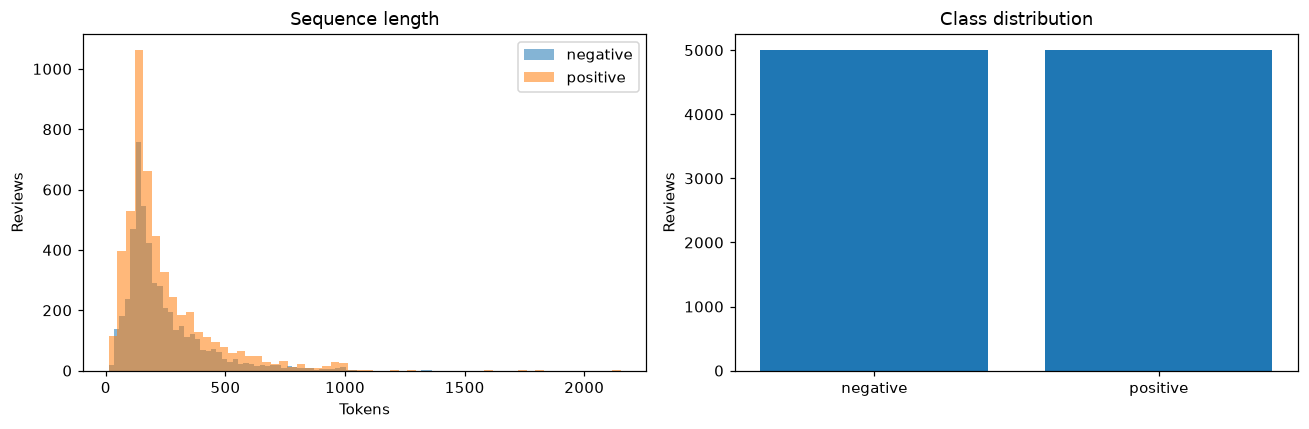


Nhận xét tham khảo: Subset cân bằng; train median=178, mean=239.1, p90=466 tokens. Chọn max_length cần xem quantiles train, tỷ lệ token giữ lại và mức truncation, sau đó kiểm tra validation; không chọn từ test.


In [2]:
data,audit=load_data(ROOT)
train=data[data.split.eq("train")].reset_index(drop=True)
validation=data[data.split.eq("validation")].reset_index(drop=True)
test=data[data.split.eq("test")].reset_index(drop=True)
table([{"check":k,"value":audit[k]} for k in ["source_labeled_samples","source_missing_text",
    "source_missing_labels","source_exact_duplicate_excess","source_normalized_duplicate_excess",
    "selected_samples","selected_normalized_duplicate_excess","seed","subset_sha256"]])
distribution=data.groupby(["split","label"]).size().rename("count").reset_index()
distribution["percentage"]=100*distribution["count"]/distribution.groupby("split")["count"].transform("sum")
table(distribution)
length_summary=data.groupby("split").length.describe(percentiles=[.25,.5,.75,.9,.95]).reset_index()
table(length_summary)
table([{"check":"subset missing text","count":int(data.text.isna().sum()+data.text.fillna("").eq("").sum())},
       {"check":"subset missing labels","count":int(data.label.isna().sum())},
       {"check":"subset normalized duplicates","count":int(data.text_hash.duplicated().sum())}])
for a,b in [("train","validation"),("train","test"),("validation","test")]:
    print(a,b,"shared hashes:",len(set(data[data.split.eq(a)].text_hash)&set(data[data.split.eq(b)].text_hash)))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for label in [0,1]:
    axes[0].hist(data[data.label.eq(label)].length,bins=60,alpha=.55,label=["negative","positive"][label])
axes[0].set_xlabel("Tokens");axes[0].set_ylabel("Reviews");axes[0].set_title("Sequence length");axes[0].legend()
axes[1].bar(["negative","positive"],[int(data.label.eq(0).sum()),int(data.label.eq(1).sum())])
axes[1].set_ylabel("Reviews");axes[1].set_title("Class distribution")
save_figure("sequence_distribution.png")
note(f"Subset cân bằng; train median={train.length.median():.0f}, mean={train.length.mean():.1f}, "
     f"p90={train.length.quantile(.9):.0f} tokens. Chọn max_length cần xem quantiles train, "
     "tỷ lệ token giữ lại và mức truncation, sau đó kiểm tra validation; không chọn từ test.")
for row in distribution.to_dict("records"):
    records.append({"record_type":"dataset_distribution",**row})
for row in length_summary.to_dict("records"):
    records.append({"record_type":"sequence_length_summary",**row})

## 12. Tokenization và vocabulary
Tokenizer giống Lab 4: lowercase, bỏ HTML, giữ từ và phủ định bằng cách chuẩn hóa n't thành not.
Vocabulary chọn theo tần suất token trên **train**, min_count=2, tối đa 10.000 IDs gồm PAD=0 và UNK=1.
PAD chỉ điền chỗ trống; UNK là từ ngoài vocabulary. Padding không có nghĩa ngôn ngữ.
Truncation giữ các token đầu, làm mất phần đuôi; hai thao tác không tương đương.
Model unidirectional lấy output tại last real timestep theo true lengths; trailing PAD không ảnh hưởng các output trước đó.

In [3]:
vocabulary=build_vocabulary(train.tokens,max_size=10000,min_count=2)
(ROOT/"data"/"vocabulary.json").write_text(json.dumps(vocabulary,ensure_ascii=False,indent=2),encoding="utf-8")
sample="I really like this movie"
ids,lengths=encode_batch([tokenize(sample)],vocabulary,8)
print("Text:",sample)
print("Tokens:",tokenize(sample))
print("IDs + PAD:",ids[0].tolist(),"| true length:",lengths[0])
print("Vocabulary IDs:",len(vocabulary),"| PAD:",PAD,"| UNK:",UNK)
print("IDs for not / no / never:",[vocabulary.get(w,UNK) for w in ["not","no","never"]])
note("PAD embedding có padding_idx=0; gather output dùng true lengths, không dùng output tại PAD. "
     "Từ test chưa thấy ở train đi qua UNK thay vì được thêm vào vocabulary.")

Text: I really like this movie
Tokens: ['i', 'really', 'like', 'this', 'movie']
IDs + PAD: [10, 65, 34, 11, 16, 0, 0, 0] | true length: 5
Vocabulary IDs: 10000 | PAD: 0 | UNK: 1
IDs for not / no / never: [13, 57, 120]

Nhận xét tham khảo: PAD embedding có padding_idx=0; gather output dùng true lengths, không dùng output tại PAD. Từ test chưa thấy ở train đi qua UNK thay vì được thêm vào vocabulary.


## 13. Experiment 2 — Padding và truncation
Đo ba max_length bắt buộc 50/100/200; thêm 30 chỉ để minh họa mức mất context.
% tokens retained = sum(min(length,L))/sum(length), không phải trung bình phần trăm mỗi review.
Bảng thời gian/accuracy/F1 sau huấn luyện nằm ở mục 20, dùng cùng các cấu hình LSTM để không train trùng.

### Trả lời câu hỏi thảo luận
Tăng length không luôn cải thiện performance trên mọi dataset. Trong lần chạy này, LSTM test F1 tăng
0,6138→0,6999→0,7494 khi L=50→100→200. Đây là kết quả quan sát, không phải bảo đảm tổng quát.
Length quá nhỏ có thể bỏ kết luận review, vế sau but hoặc từ khóa sentiment nằm ngoài prefix.


     split  max_length  tokens_retained_percent  mean_review_retained_percent  reviews_truncated_percent  padding_percent  retained_oov_percent
     train          30                  12.5446                       19.0237                    99.8000           0.0394                4.4223
     train          50                  20.8453                       31.2749                    97.8000           0.3377                4.6791
     train         100                  40.3446                       56.8367                    88.2833           3.5555                4.8767
     train         200                  67.2110                       83.6184                    42.9833          19.6654                5.0934
validation          30                  12.9183                       19.6420                    99.8500           0.0450                5.2557
validation          50                  21.4453                       32.1816                    97.4000           0.4410               

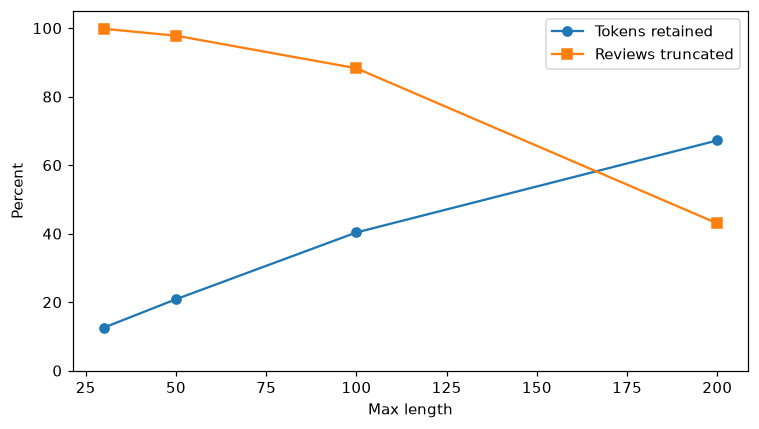


Nhận xét tham khảo: L nhỏ có thể mất kết luận cuối review, từ sentiment hoặc vế sau but. Giữ thêm token không đảm bảo F1 tăng vì nhiễu, chi phí và khả năng học của model cũng thay đổi.


In [4]:
retention_rows=[]
for split,frame in [("train",train),("validation",validation),("test",test)]:
    for length in [30,50,100,200]:
        row={"split":split,**retention(frame.tokens.tolist(),vocabulary,length)}
        retention_rows.append(row)
        records.append({"record_type":"retention",**row})
table(retention_rows)
train_ret=pd.DataFrame(retention_rows).query("split == 'train'")
plt.figure(figsize=(7,4))
plt.plot(train_ret.max_length,train_ret.tokens_retained_percent,marker="o",label="Tokens retained")
plt.plot(train_ret.max_length,train_ret.reviews_truncated_percent,marker="s",label="Reviews truncated")
plt.xlabel("Max length");plt.ylabel("Percent");plt.ylim(0,105);plt.legend()
save_figure("retention.png")
note("L nhỏ có thể mất kết luận cuối review, từ sentiment hoặc vế sau but. "
     "Giữ thêm token không đảm bảo F1 tăng vì nhiễu, chi phí và khả năng học của model cũng thay đổi.")

## 14. Core implementation — Simple RNN cell
rnn_cell.py tự cài đặt forward bằng NumPy; training classifier bên dưới dùng PyTorch.
Ví dụ dùng đúng số liệu bài tính tay, sau đó gán cùng weights vào torch.nn.RNNCell để so sánh.
PyTorch có hai bias; đặt bias_ih=b_h và bias_hh=0 để tổng bias giống công thức.

In [5]:
cell=SimpleRNNCell(2,2)
cell.W_xh=np.array([[.5,.2],[.1,.4]])
cell.W_hh=np.array([[.3,.1],[.2,.5]])
cell.b_h=np.zeros(2)
x=np.array([1.,0.]);previous=np.array([.5,.2])
a=cell.W_xh@x+cell.W_hh@previous
ours=cell.forward(x,previous)
framework=nn.RNNCell(2,2,nonlinearity="tanh").double()
with torch.no_grad():
    framework.weight_ih.copy_(torch.tensor(cell.W_xh))
    framework.weight_hh.copy_(torch.tensor(cell.W_hh))
    framework.bias_ih.copy_(torch.tensor(cell.b_h))
    framework.bias_hh.zero_()
    expected=framework(torch.tensor(x)[None,:],torch.tensor(previous)[None,:]).numpy()[0]
table([{"component":f"h[{i}]","a":a[i],"NumPy":ours[i],"PyTorch":expected[i],
        "absolute difference":abs(ours[i]-expected[i])} for i in range(2)])
difference=float(np.max(np.abs(ours-expected)))
print("Matching within 1e-10:",np.allclose(ours,expected,atol=1e-10,rtol=0))
if difference>1e-10:
    raise ValueError("RNN cell forward differs from framework")
for i in range(2):
    records.append({"record_type":"rnn_cell_check","component":i,"preactivation":a[i],
                    "numpy_hidden":ours[i],"torch_hidden":expected[i],"absolute_difference":abs(ours[i]-expected[i])})
# Same bag of token vectors, different sequence order.
toy={"dog":np.array([1.,0.]),"bites":np.array([.1,.8]),"man":np.array([0.,1.])}
for words in [["dog","bites","man"],["man","bites","dog"]]:
    hidden=np.zeros(2);states=[]
    for word in words:
        hidden=cell.forward(toy[word],hidden)
        states.append(hidden.tolist())
    print(" ".join(words),"| average:",np.mean([toy[w] for w in words],axis=0),"| final hidden:",hidden)
    for t,state in enumerate(states,1):
        records.append({"record_type":"toy_information_flow","sequence":" ".join(words),"timestep":t,
                        "token":words[t-1],"hidden_0":state[0],"hidden_1":state[1]})
note("Average giống nhau khi chỉ hoán vị từ; recurrence dùng h trước đó nên hidden cuối có thể khác. "
     "Toy weights không chứng minh model đã học ngữ nghĩa subject/object.")

component    a  NumPy  PyTorch  absolute difference
     h[0] 0.67 0.5850   0.5850                  0.0
     h[1] 0.30 0.2913   0.2913                  0.0
Matching within 1e-10: True
dog bites man | average: [0.36666667 0.6       ] | final hidden: [0.33388713 0.59721514]
man bites dog | average: [0.36666667 0.6       ] | final hidden: [0.56498483 0.39132473]

Nhận xét tham khảo: Average giống nhau khi chỉ hoán vị từ; recurrence dùng h trước đó nên hidden cuối có thể khác. Toy weights không chứng minh model đã học ngữ nghĩa subject/object.


## 15. Experiment 3 — Baseline TF-IDF + LR và RNN
Baseline đúng cấu hình Lab 4: unigram max_features=10k, min_df=2, sublinear TF, L2, LR C=1/liblinear.
Sequence model: trainable random embeddings, 64 chiều, hidden 64, 1 layer, unidirectional, dropout 0.2 sau hidden,
batch 128, Adam lr=0.002, 8 epochs, gradient clipping=1, seed 2026, CPU 4 threads.
Không dùng pretrained embedding. Vocabulary/split giống nhau giữa recurrent models; embedding được khởi tạo cùng seed.
Checkpoint chọn bằng **validation loss nhỏ nhất**, không dùng test. Tất cả model vẫn chạy đủ 8 epochs.

TF-IDF dùng toàn bộ review; recurrent classifier dùng prefix đã truncate. Chênh lệch metrics vì vậy bao gồm ảnh hưởng mất context, representation và training, không chỉ recurrent architecture.

### RNN có dùng thông tin sequence không?
Toy dog bites man/man bites dog cho cùng average nhưng hidden cuối khác.
Ở probe cùng multiset 91 tokens, RNN có P(positive) cho excellent ở đầu/giữa/cuối là 0,2852/0,2589/0,5995,
trong khi TF-IDF là 0,7948 ở cả ba vị trí. Đây là bằng chứng output nhạy với vị trí;
không chứng minh model hiểu đúng quan hệ ngữ nghĩa. Test F1 của RNN=0,5913 vẫn thấp hơn baseline=0,8751.


In [6]:
baseline=fit_baseline(train,validation)
sequence_models[("RNN",100)]=fit_sequence("RNN",100,train,validation,vocabulary,ROOT)
table([metric_row(baseline,"validation"),metric_row(sequence_models[("RNN",100)],"validation")])
note("Bằng chứng về word order gồm NumPy toy ở mục 14 và probe cùng multiset từ ở mục 21. "
     "Architecture sử dụng thứ tự không đồng nghĩa luôn hiểu ngữ pháp hoặc đạt accuracy cao hơn TF-IDF.")

Loaded completed RNN length=100; best epoch=4


record_type       model      split  seed architecture  max_length  embedding_dimension  hidden_dimension  vocabulary_size  parameters  epochs  best_epoch  training_seconds  fit_seconds  validation_loss  parameter_mib  sampled_process_rss_mib                            metric_average  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
 evaluation TF-IDF + LR validation  2026           LR         NaN                  NaN               NaN            10000       10001     NaN         NaN            2.8057       2.8057              NaN            NaN                      NaN binary positive=1; macro_f1 also reported    0.8745     0.8577   0.898 0.8774    0.8744 851 149 102 898
 evaluation   RNN L=100 validation  2026          RNN       100.0                 64.0              64.0            10000      648385     8.0         4.0           19.1719      17.2759            0.685         2.4734                 566.7695 binary positive=1; macro_f1 also reported    0.5780     0.5802   0

## 19. Experiment 4 — RNN vs LSTM vs GRU
Cùng L=100 và cùng mọi hyperparameter nêu ở mục 15; chỉ đổi recurrent architecture.
Báo số tham số, thời gian, accuracy, precision, recall, F1 và macro-F1; không chỉ chọn theo accuracy.
Checkpoint cache có fingerprint config, source code, vocabulary và dataset; chỉ reuse khi trùng toàn bộ fingerprint.

### Kết quả có phù hợp prediction mẫu không?
Với L=100, test F1 RNN/LSTM/GRU=0,5913/0,6999/0,7021: gated models tốt hơn RNN trong cấu hình này,
phù hợp kỳ vọng về khả năng giữ/cập nhật thông tin. Đây không phải bằng chứng độc lập rằng khác biệt do long-range dependency,
vì còn optimization, capacity và regularization. Sinh viên tự đối chiếu với prediction thực sự đã ghi.
Parameters tương ứng 648.385/673.345/665.025; GRU ít parameters hơn LSTM nhưng train lâu hơn ở máy/runtime này.


Loaded completed LSTM length=100; best epoch=4


Loaded completed GRU length=100; best epoch=5


record_type      model      split  seed architecture  max_length  embedding_dimension  hidden_dimension  vocabulary_size  parameters  epochs  best_epoch  training_seconds  fit_seconds  validation_loss  parameter_mib  sampled_process_rss_mib                            metric_average  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
 evaluation  RNN L=100 validation  2026          RNN         100                   64                64            10000      648385       8           4           19.1719      17.2759           0.6850         2.4734                 566.7695 binary positive=1; macro_f1 also reported    0.5780     0.5802   0.564 0.5720    0.5779 592 408 436 564
 evaluation LSTM L=100 validation  2026         LSTM         100                   64                64            10000      673345       8           4           23.9928      21.7983           0.6244         2.5686                 574.7812 binary positive=1; macro_f1 also reported    0.6815     0.6561   0.76

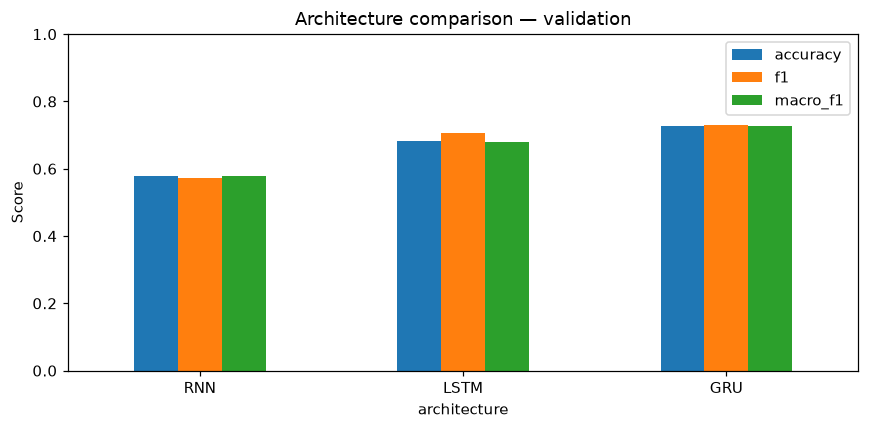


Nhận xét tham khảo: Đối chiếu bảng với prediction cá nhân. Gates là khác biệt cơ chế; kết quả một seed và lịch train cố định chưa chứng minh LSTM/GRU luôn tốt hơn RNN.


In [ ]:
for architecture in ["LSTM","GRU"]:
    sequence_models[(architecture,100)]=fit_sequence(architecture,100,train,validation,vocabulary,ROOT)
architecture_rows=[metric_row(sequence_models[(arch,100)],"validation") for arch in ["RNN","LSTM","GRU"]]
table(architecture_rows)
pd.DataFrame(architecture_rows).set_index("architecture")[["accuracy","f1","macro_f1"]].plot.bar(figsize=(8,4),ylim=(0,1),rot=0)
plt.title("Architecture comparison — validation");plt.ylabel("Score")
save_figure("architecture_validation.png")


## 20. Experiment 5 — Sequence length
Giữ architecture LSTM, chỉ đổi L=50/100/200. Bảng retention đã tính ở mục 13.
Huấn luyện đủ 8 epochs và chọn checkpoint min validation loss cho từng cấu hình.
Memory gồm parameter MiB và process RSS lấy mẫu sau epoch; RSS chứa toàn bộ Python process, không phải peak riêng chính xác từng model.

### Trade-off context và cost
LSTM L=50/100/200 giữ 20,85%/40,34%/67,21% tokens train; train-loop time khoảng 12,85/23,99/57,63 giây.
Giữ thêm context cải thiện F1 trong lần này nhưng tăng cost; parameters vẫn là 673.345 cho cả ba.
Thời gian bao gồm validation và warm-up nên không diễn giải tỷ lệ runtime thành định luật tuyến tính chính xác.


In [8]:
for length in [50,200]:
    sequence_models[("LSTM",length)]=fit_sequence("LSTM",length,train,validation,vocabulary,ROOT)
length_val=[]
for length in [50,100,200]:
    item=sequence_models[("LSTM",length)]
    length_val.append({**metric_row(item,"validation"),**retention(train.tokens.tolist(),vocabulary,length)})
table(length_val)
note("Thêm context tăng lượng token xử lý, nhưng số parameters không đổi vì weights được chia sẻ theo timestep. "
     "Training time và F1 cuối cùng được đối chiếu sau khi mở test; giữ nguyên config, không chọn length bằng test.")

Loaded completed LSTM length=50; best epoch=4


Loaded completed LSTM length=200; best epoch=6


record_type      model      split  seed architecture  max_length  embedding_dimension  hidden_dimension  vocabulary_size  parameters  epochs  best_epoch  training_seconds  fit_seconds  validation_loss  parameter_mib  sampled_process_rss_mib                            metric_average  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp  tokens_retained_percent  mean_review_retained_percent  reviews_truncated_percent  padding_percent  retained_oov_percent
 evaluation  LSTM L=50 validation  2026         LSTM          50                   64                64            10000      673345       8           4           12.8475      11.7932           0.6515         2.5686                 602.0156 binary positive=1; macro_f1 also reported    0.6510     0.6724   0.589 0.6279    0.6497 713 287 411 589                  20.8453                       31.2749                    97.8000           0.3377                4.6791
 evaluation LSTM L=100 validation  2026         LSTM         100    

## 21. Experiment 6 — Long-range dependency và word order
Probe tổng hợp giữ cùng multiset từ, di chuyển excellent/terrible tới đầu/giữa/cuối trong 91 tokens;
L=100 nên cue còn nguyên cho mọi model được so sánh.
Thêm probe cue ở sau token 150 để phân biệt **bị truncate** với **khó giữ thông tin qua recurrence**.
Các câu nhân tạo lệch miền và không chứng minh đầy đủ vanishing gradient.

### Diễn giải probe
TF-IDF bất biến theo vị trí vì bag-of-words không đổi. Các recurrent outputs thay đổi nhưng có hành vi không phù hợp sentiment:
ví dụ GRU cho excellent ở giữa/cuối P thấp. Repeated filler là input nhân tạo lệch miền.
Trong probe cue ở token 151, LSTM50/100 cho cùng P khi thay excellent bằng terrible vì cả hai cue đều bị bỏ.
LSTM200 nhìn thấy cue nên hai P khác nhau (0,9401 và 0,6483), nhưng terrible vẫn bị đoán positive.
Không suy ra model đã hiểu negation hoặc chứng minh vanishing gradient từ những ví dụ này.


      model       cue  position  tokens  cue_retained  probability
TF-IDF + LR excellent beginning      91          True       0.7948
  RNN L=100 excellent beginning      91          True       0.2852
 LSTM L=100 excellent beginning      91          True       0.7357
  GRU L=100 excellent beginning      91          True       0.7182
TF-IDF + LR excellent    middle      91          True       0.7948
  RNN L=100 excellent    middle      91          True       0.2589
 LSTM L=100 excellent    middle      91          True       0.7359
  GRU L=100 excellent    middle      91          True       0.0458
TF-IDF + LR excellent       end      91          True       0.7948
  RNN L=100 excellent       end      91          True       0.5995
 LSTM L=100 excellent       end      91          True       0.7515
  GRU L=100 excellent       end      91          True       0.1079
TF-IDF + LR  terrible beginning      91          True       0.5326
  RNN L=100  terrible beginning      91          True       0.

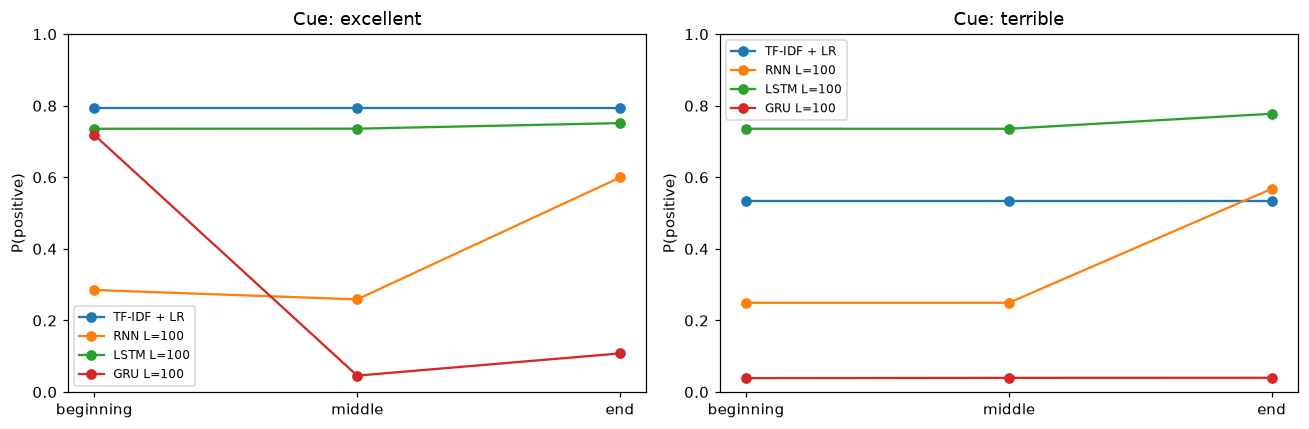

   record_type      model       cue  tokens  cue_retained  probability
late_cue_probe  LSTM L=50 excellent     151         False       0.6399
late_cue_probe LSTM L=100 excellent     151         False       0.7729
late_cue_probe LSTM L=200 excellent     151          True       0.9401
late_cue_probe  LSTM L=50  terrible     151         False       0.6399
late_cue_probe LSTM L=100  terrible     151         False       0.7729
late_cue_probe LSTM L=200  terrible     151          True       0.6483
         record_type       model                   text  probability  prediction
order_negation_probe TF-IDF + LR     this movie is good       0.4894           0
order_negation_probe TF-IDF + LR     good is this movie       0.4894           0
order_negation_probe TF-IDF + LR this movie is not good       0.3006           0
order_negation_probe TF-IDF + LR  this movie is not bad       0.0082           0
order_negation_probe   RNN L=100     this movie is good       0.2614           0
order_negation_pr

In [9]:
filler=("the movie has scenes with people and a story ".split())*10
position_rows=[]
for cue in ["excellent","terrible"]:
    for position,index in [("beginning",0),("middle",45),("end",90)]:
        words=filler.copy();words.insert(index,cue)
        text=" ".join(words)
        baseline_prob=float(predict_baseline(baseline,[text])[0])
        position_rows.append({"record_type":"position_probe","model":baseline["name"],"cue":cue,
                              "position":position,"tokens":len(words),"cue_retained":True,
                              "probability":baseline_prob,"text":text})
        for arch in ["RNN","LSTM","GRU"]:
            item=sequence_models[(arch,100)]
            probability=float(predict_sequence(item,[text],vocabulary)[0])
            position_rows.append({"record_type":"position_probe","model":item["name"],"cue":cue,
                "position":position,"tokens":len(words),"cue_retained":True,
                "probability":probability,"text":text})
table(pd.DataFrame(position_rows).drop(columns=["record_type","text"]))
records.extend(position_rows)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,cue in zip(axes,["excellent","terrible"]):
    frame=pd.DataFrame(position_rows).query("cue == @cue")
    for name,group in frame.groupby("model",sort=False):
        ax.plot(group.position,group.probability,marker="o",label=name)
    ax.set_title("Cue: "+cue);ax.set_ylim(0,1);ax.set_ylabel("P(positive)");ax.legend(fontsize=8)
save_figure("position_probe.png")
late_rows=[]
for cue in ["excellent","terrible"]:
    text=" ".join(filler+filler[:60]+[cue])
    for length in [50,100,200]:
        item=sequence_models[("LSTM",length)]
        late_rows.append({"record_type":"late_cue_probe","model":item["name"],"cue":cue,"tokens":151,
                         "cue_retained":length>=151,"probability":float(predict_sequence(item,[text],vocabulary)[0])})
table(late_rows);records.extend(late_rows)
order_texts=["this movie is good","good is this movie","this movie is not good","this movie is not bad"]
order_rows=[]
for item in [baseline]+[sequence_models[(a,100)] for a in ["RNN","LSTM","GRU"]]:
    probs=predict_baseline(item,order_texts) if item is baseline else predict_sequence(item,order_texts,vocabulary)
    for text,probability in zip(order_texts,probs):
        order_rows.append({"record_type":"order_negation_probe","model":item["name"],"text":text,
                           "probability":float(probability),"prediction":int(probability>=.5)})
table(order_rows);records.extend(order_rows)
note("TF-IDF unigram bất biến với cùng multiset từ. Recurrent probabilities có thể đổi theo vị trí/thứ tự. "
     "Khi cue bị truncate thì inputs của excellent/terrible giống nhau, nên không thể quy lỗi đó cho vanishing gradient. "
     "Probe nhỏ chỉ là empirical observation, không đo trực tiếp gradient xa.")

## 22. Evaluation — khóa config trước test
Chọn LSTM/GRU dùng cho application bằng validation macro-F1; checkpoint từng model đã chọn bằng validation loss.
Không tune trên test, không refit train+validation. Báo toàn bộ năm recurrent configs và baseline trên cùng 2.000 test reviews.
Precision/Recall/F1 là binary positive=1; macro-F1 báo thêm. Train loop time gồm validation mỗi epoch,
fit_seconds tách riêng phần cập nhật weights; thời gian baseline chỉ gồm vectorizer+fit LR.

### Nhận xét metrics
GRU100 được chọn theo validation macro-F1=0,7285, test F1=0,7021.
LSTM200 có test F1=0,7494 cao hơn, nhưng không đổi application model sau khi xem test.
Baseline full-review TF-IDF/LR có F1=0,8751; recurrent pipeline random embeddings và truncated prefixes chưa vượt baseline.
So sánh này gồm cả ảnh hưởng mất context và lịch train, không chỉ architecture.


LOCKED application model: GRU L=100 | validation macro-F1: 0.7284754949134159


record_type       model split  seed architecture  max_length  embedding_dimension  hidden_dimension  vocabulary_size  parameters  epochs  best_epoch  training_seconds  fit_seconds  validation_loss  parameter_mib  sampled_process_rss_mib                            metric_average  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
 evaluation TF-IDF + LR  test  2026           LR         NaN                  NaN               NaN            10000       10001     NaN         NaN            2.8057       2.8057              NaN            NaN                      NaN binary positive=1; macro_f1 also reported    0.8740     0.8674   0.883 0.8751    0.8740 865 135 117 883
 evaluation   RNN L=100  test  2026          RNN       100.0                 64.0              64.0            10000      648385     8.0         4.0           19.1719      17.2759           0.6850         2.4734                 566.7695 binary positive=1; macro_f1 also reported    0.5880     0.5866   0.596 0.5913    

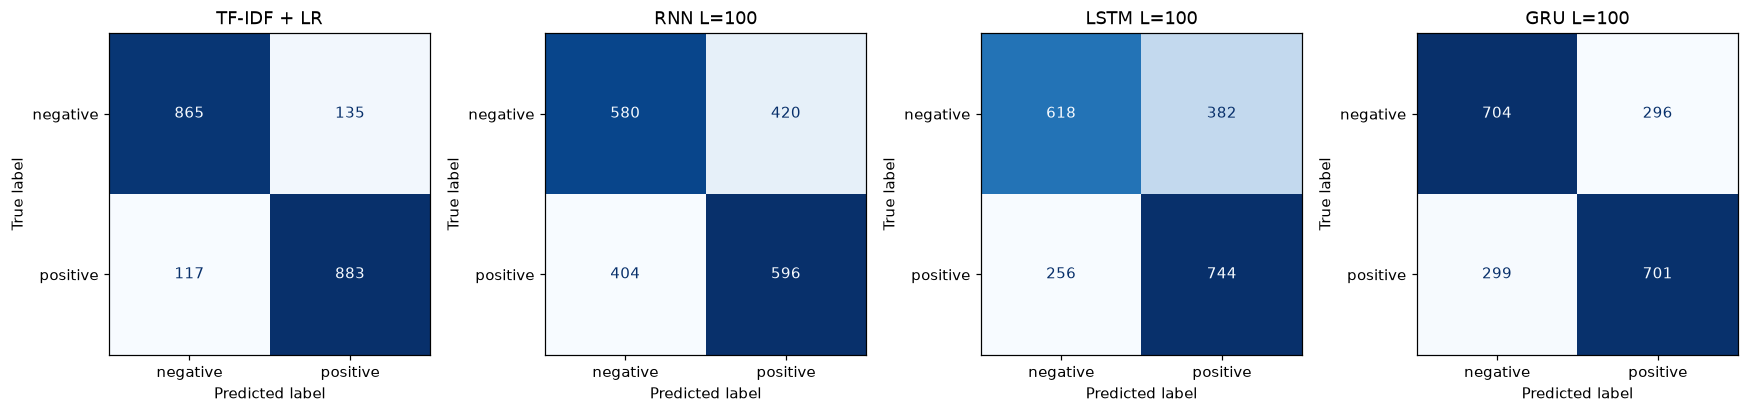


Nhận xét tham khảo: Application model chọn từ validation là GRU L=100; test accuracy=0.7025, precision=0.7031, recall=0.7010, F1=0.7021. Architecture có thể dùng thứ tự nhưng vẫn thua TF-IDF khi dữ liệu/lịch train/regularization chưa phù hợp.


In [10]:
selected=max([m for m in sequence_models.values() if m["architecture"] in ["LSTM","GRU"]],
             key=lambda m:(m["validation"]["macro_f1"],-m["validation_loss"]))
print("LOCKED application model:",selected["name"],"| validation macro-F1:",selected["validation"]["macro_f1"])
all_models=[baseline]+list(sequence_models.values())
for item in all_models:
    probability=(predict_baseline(item,test.text.tolist()) if item is baseline
                 else predict_sequence(item,test.text.tolist(),vocabulary))
    item["test_probability"]=probability
    item["test_pred"]=(probability>=.5).astype(int)
    item["test"]=metrics(test.label,probability)
    for split in ["validation","test"]:
        records.append(metric_row(item,split))
evaluation=pd.DataFrame([metric_row(item,"test") for item in all_models])
table(evaluation)
for item in [baseline]+[sequence_models[(arch,100)] for arch in ["RNN","LSTM","GRU"]]:
    print("\n",item["name"])
    print(classification_report(test.label,item["test_pred"],target_names=["negative","positive"],digits=4,zero_division=0))
fig,axes=plt.subplots(1,4,figsize=(16,4))
for ax,item in zip(axes,[baseline]+[sequence_models[(a,100)] for a in ["RNN","LSTM","GRU"]]):
    ConfusionMatrixDisplay(confusion_matrix(test.label,item["test_pred"],labels=[0,1]),
        display_labels=["negative","positive"]).plot(ax=ax,cmap="Blues",colorbar=False)
    ax.set_title(item["name"])
save_figure("confusion_matrix.png")
note(f"Application model chọn từ validation là {selected['name']}; test accuracy={selected['test']['accuracy']:.4f}, "
     f"precision={selected['test']['precision']:.4f}, recall={selected['test']['recall']:.4f}, F1={selected['test']['f1']:.4f}. "
     "Architecture có thể dùng thứ tự nhưng vẫn thua TF-IDF khi dữ liệu/lịch train/regularization chưa phù hợp.")

record_type      model split  seed architecture  max_length  embedding_dimension  hidden_dimension  vocabulary_size  parameters  epochs  best_epoch  training_seconds  fit_seconds  validation_loss  parameter_mib  sampled_process_rss_mib                            metric_average  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp  tokens_retained_percent  mean_review_retained_percent  reviews_truncated_percent  padding_percent  retained_oov_percent
 evaluation  LSTM L=50  test  2026         LSTM          50                   64                64            10000      673345       8           4           12.8475      11.7932           0.6515         2.5686                 602.0156 binary positive=1; macro_f1 also reported    0.6395     0.6609   0.573 0.6138    0.6379 706 294 427 573                  20.8453                       31.2749                    97.8000           0.3377                4.6791
 evaluation LSTM L=100  test  2026         LSTM         100                   

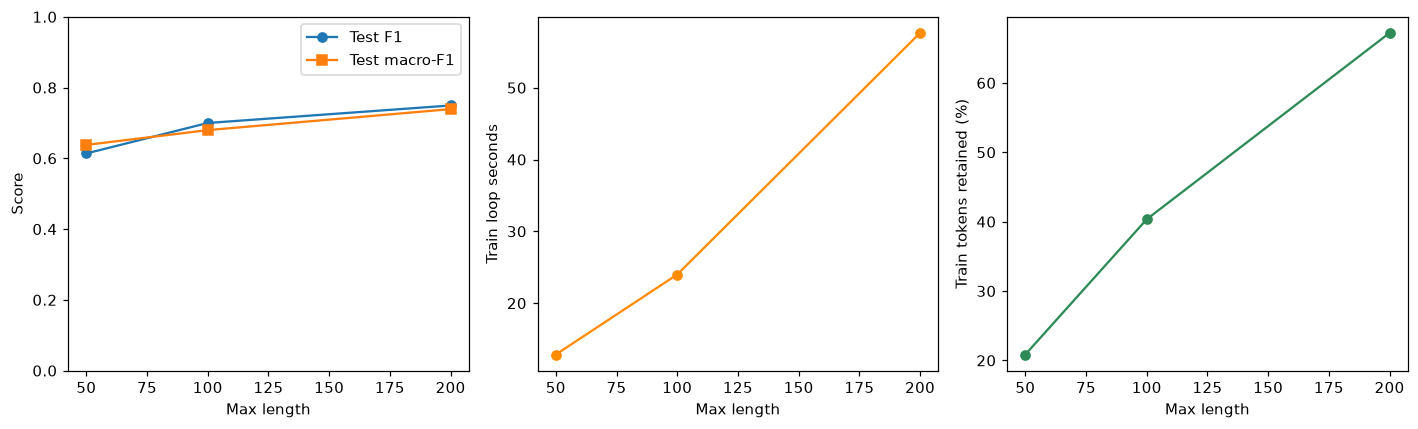


Nhận xét tham khảo: F1 theo L=50/100/200: 0.6138/0.6999/0.7494. Cần cân nhắc context giữ lại, cost và validation loss; tăng length không đảm bảo tốt hơn. Không dùng test để thay lựa chọn.


In [11]:
length_test=[]
for length in [50,100,200]:
    item=sequence_models[("LSTM",length)]
    length_test.append({**metric_row(item,"test"),**retention(train.tokens.tolist(),vocabulary,length)})
table(length_test)
length_df=pd.DataFrame(length_test)
fig,axes=plt.subplots(1,3,figsize=(13,4))
axes[0].plot(length_df.max_length,length_df.f1,marker="o",label="Test F1")
axes[0].plot(length_df.max_length,length_df.macro_f1,marker="s",label="Test macro-F1")
axes[0].set_ylabel("Score");axes[0].set_ylim(0,1);axes[0].legend()
axes[1].plot(length_df.max_length,length_df.training_seconds,marker="o",color="darkorange")
axes[1].set_ylabel("Train loop seconds")
axes[2].plot(length_df.max_length,length_df.tokens_retained_percent,marker="o",color="seagreen")
axes[2].set_ylabel("Train tokens retained (%)")
for ax in axes:ax.set_xlabel("Max length")
save_figure("sequence_length_comparison.png")
f1_values=length_df.f1.tolist()
note("F1 theo L=50/100/200: "+"/".join(f"{x:.4f}" for x in f1_values)+
     ". Cần cân nhắc context giữ lại, cost và validation loss; tăng length không đảm bảo tốt hơn. Không dùng test để thay lựa chọn.")

## 23. Learning curves
Vẽ train loss và validation loss của tất cả cấu hình. Train loss là trung bình loss các minibatch trong epoch khi dropout bật;
validation loss đo cuối epoch ở eval mode. Vì vậy không kỳ vọng hai đường có thể so sánh như cùng một phép đo.
Best epoch được đánh dấu theo validation loss. Xem cả tiến trình thay vì chỉ epoch cuối.


Nhận xét tham khảo: RNN L=100: train loss 0.7014→0.4950; min validation=0.6850 ở epoch 4; validation cuối cao hơn min 0.0694. Train giảm nhưng validation tăng sau điểm tốt nhất là dấu hiệu có thể overfit.

Nhận xét tham khảo: LSTM L=100: train loss 0.6942→0.2321; min validation=0.6244 ở epoch 4; validation cuối cao hơn min 0.0864. Train giảm nhưng validation tăng sau điểm tốt nhất là dấu hiệu có thể overfit.

Nhận xét tham khảo: GRU L=100: train loss 0.6948→0.1679; min validation=0.5704 ở epoch 5; validation cuối cao hơn min 0.0959. Train giảm nhưng validation tăng sau điểm tốt nhất là dấu hiệu có thể overfit.

Nhận xét tham khảo: LSTM L=50: train loss 0.6908→0.1800; min validation=0.6515 ở epoch 4; validation cuối cao hơn min 0.2752. Train giảm nhưng validation tăng sau điểm tốt nhất là dấu hiệu có thể overfit.

Nhận xét tham khảo: LSTM L=200: train loss 0.6905→0.2116; min validation=0.5822 ở epoch 6; validation cuối cao hơn min 0.0349. Train giảm nhưng validation tăng sau điểm tốt n

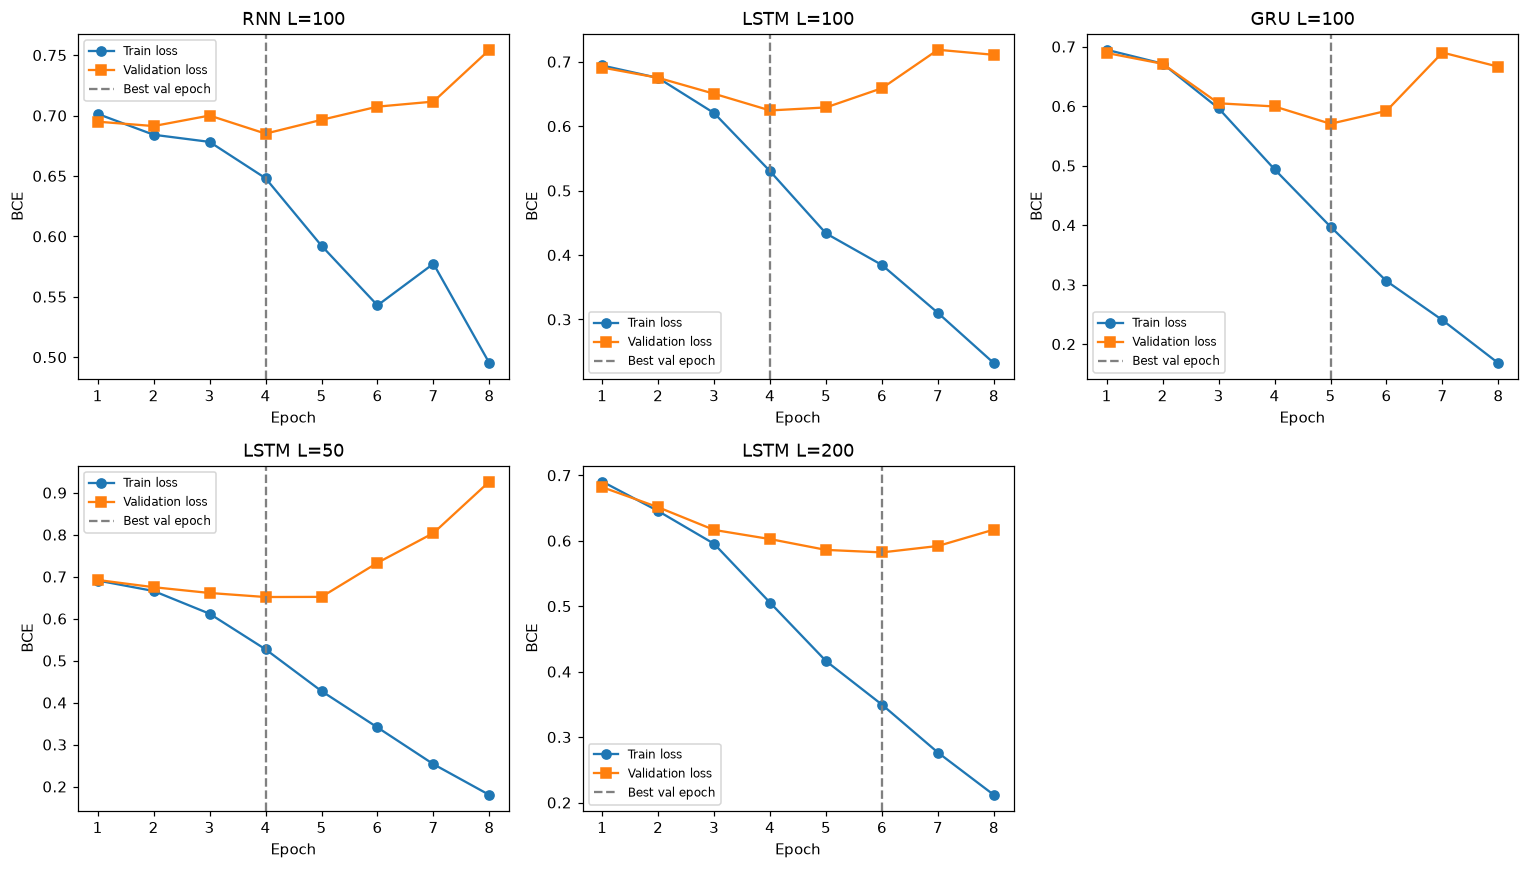

In [12]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,item in zip(axes.flat,sequence_models.values()):
    history=pd.DataFrame(item["history"])
    ax.plot(history.epoch,history.train_loss,marker="o",label="Train loss")
    ax.plot(history.epoch,history.validation_loss,marker="s",label="Validation loss")
    ax.axvline(item["best_epoch"],ls="--",color="grey",label="Best val epoch")
    ax.set_title(item["name"]);ax.set_xlabel("Epoch");ax.set_ylabel("BCE");ax.legend(fontsize=8)
    for row in item["history"]:
        records.append({"record_type":"learning_curve",**row})
    first=history.iloc[0];last=history.iloc[-1]
    gap=float(last.validation_loss-history.validation_loss.min())
    note(f"{item['name']}: train loss {first.train_loss:.4f}→{last.train_loss:.4f}; "
         f"min validation={history.validation_loss.min():.4f} ở epoch {item['best_epoch']}; "
         f"validation cuối cao hơn min {gap:.4f}. "
         +("Train giảm nhưng validation tăng sau điểm tốt nhất là dấu hiệu có thể overfit."
           if last.train_loss<first.train_loss and gap>.02 else
           "Chưa nên kết luận overfit chỉ từ một điểm; xem đường loss và checkpoint đã chọn."))
axes.flat[-1].axis("off")
save_figure("learning_curves.png")

## 24. Error analysis — ba đúng và ba sai
Dùng application model đã khóa. Chọn ví dụ bao phủ hai nhãn và lỗi FP/FN khi có.
Mỗi review có nguyên văn, phần model nhìn thấy, original length, truncation, OOV, probability và kết quả baseline.
So sánh head với tail **chỉ là diagnostic sau đánh giá**, không thay preprocessing của model chính.
Không gán mọi lỗi cho sequence modeling; phân biệt mất thông tin vì truncation, từ lạ và suy luận ngữ cảnh.

In [13]:
case_discussions={'aclImdb/test/neg/3254_1.txt': 'Worst sequel, unfunny và acting stinks là lời chê rõ; review 23 tokens không bị truncate, OOV=0. GRU và baseline đều đúng nên chưa có bằng chứng rằng cần long-range modeling cho trường hợp này.', 'aclImdb/test/pos/9148_9.txt': 'Love và great thể hiện lời khen, model dự đoán positive phù hợp. OOV khoảng 15,38% không ngăn dự đoán đúng; không thể suy ra cứ có OOV là model sẽ sai.', 'aclImdb/test/neg/11010_3.txt': "Review có disappointment, disjointed, very bad knock-off và gave up trong retained prefix. Chỉ token cuối 'is' bị bỏ; không có bằng chứng phần mất này quyết định sentiment. Predicted negative phù hợp nội dung dù OOV prefix=12%.", 'aclImdb/test/neg/7086_4.txt': 'P=0,5061 rất gần threshold nên là quyết định yếu. Review chuyển từ intelligent summation sang phần kết khó diễn giải; khoảng 20,93% token retained là OOV. Không bị truncate và baseline cũng sai. Các bằng chứng này hỗ trợ xem xét ambiguity/vocabulary, chưa chứng minh lỗi riêng do sequence modeling hay sarcasm.', 'aclImdb/test/pos/7417_7.txt': "Review khen club scenes extremely believable và đặt câu hỏi What more do you require from an evening's entertainment. Drugs/violence mô tả nội dung, không nhất thiết chê phim. Model P=0,4687 sát threshold, baseline cũng sai và không có truncation. Giả thuyết là tín hiệu domain/context pha trộn; cần thêm diagnostic để khẳng định từ nào gây sai.", 'aclImdb/test/neg/8440_1.txt': 'Retained prefix đã có tragic pile, hollow and stale, turn it off và unfortunately; chỉ mất token cuối reclaim. Vì nội dung chê vẫn hiện diện và baseline dự đoán đúng, không hợp lý mặc định lỗi do truncation. GRU có thể chưa tổng hợp tốt context hoặc các cấu trúc not only/but, nhưng chưa có bằng chứng đủ để quy về một cơ chế duy nhất.'}
actual=test.label.to_numpy();pred=selected["test_pred"]
example_indices=[]
for correct in [True,False]:
    candidates=np.flatnonzero((actual==pred)==correct).tolist()
    chosen=[]
    for label in [0,1]:
        group=[i for i in candidates if actual[i]==label]
        if group:chosen.append(min(group,key=lambda i:(test.iloc[i].length,i)))
    remaining=[i for i in candidates if i not in chosen]
    long=[i for i in remaining if test.iloc[i].length>selected["max_length"]]
    if long:chosen.append(min(long,key=lambda i:(test.iloc[i].length,i)))
    elif remaining:chosen.append(remaining[0])
    example_indices.extend(chosen[:3])
error_rows=[];error_document=["# 24. Error analysis — bản tham khảo",
    f"Model: {selected['name']}; seed=2026; checkpoint epoch={selected['best_epoch']}; threshold=0.5."]
for number,i in enumerate(example_indices,1):
    row=test.iloc[i];words=row.tokens;limit=selected["max_length"]
    visible=words[:limit];removed=words[limit:]
    head_probability=float(selected["test_probability"][i])
    tail_probability=float(predict_sequence(selected,[" ".join(words[-limit:])],vocabulary)[0])
    oov=sum(w not in vocabulary for w in visible)/max(len(visible),1)
    context_terms=[w for w in ["not","no","never","but","however","although"] if w in words]
    explanation=(f"Model dùng {len(visible)}/{len(words)} tokens; retained OOV={oov:.2%}. "
        f"Context markers: {', '.join(context_terms) or 'không có trong danh sách khảo sát'}. "
        f"P(positive) head={head_probability:.4f}, tail diagnostic={tail_probability:.4f}. ")
    if len(removed):
        explanation+="Review bị truncate; cần đọc phần đuôi để xem cue quyết định có bị mất không. Khác biệt head/tail chưa chứng minh nguyên nhân duy nhất. "
    else:
        explanation+="Không bị truncate nên không thể quy lỗi cho mất phần đuôi; cần xem lexical ambiguity, scope phủ định, dữ liệu và lịch train. "
    explanation+="Đây là bản phân tích có bằng chứng quan sát, chưa khẳng định lỗi là do sequence modeling hay sarcasm."
    explanation += " Đọc review cụ thể: " + case_discussions.get(row.id,"")
    info={"record_type":"error_analysis","model":selected["name"],"case":number,"id":row.id,
          "true_label":int(row.label),"prediction":int(pred[i]),"correct":bool(pred[i]==actual[i]),
          "probability":head_probability,"baseline_prediction":int(baseline["test_pred"][i]),
          "original_length":len(words),"retained_length":len(visible),"truncated":bool(removed),
          "oov_fraction":oov,"tail_probability":tail_probability,
          "text":row.text,"retained_text":" ".join(visible),"removed_text":" ".join(removed),"analysis":explanation}
    error_rows.append(info);records.append(info)
    print("\nCASE",number,"| true",actual[i],"pred",pred[i],"| ID",row.id)
    print("FULL:",row.text)
    print("MODEL SEES:"," ".join(visible))
    print("REMOVED:"," ".join(removed) or "[none]")
    print("Phân tích tham khảo:",explanation)
    error_document.extend([f"## Ví dụ {number} — {'Đúng' if info['correct'] else 'Sai'}",
        f"ID: {row.id}; true={actual[i]}, predicted={pred[i]}, P(positive)={head_probability:.4f}.",
        "### Full review\n\n"+row.text,"### Model sees\n\n"+" ".join(visible),
        "### Removed\n\n"+(" ".join(removed) or "[none]"),"### Phân tích tham khảo\n\n"+explanation])
table(pd.DataFrame(error_rows).drop(columns=["record_type","text","retained_text","removed_text","analysis"]))
(ROOT/"error_analysis.md").write_text("\n\n".join(error_document),encoding="utf-8")


CASE 1 | true 0 pred 0 | ID aclImdb/test/neg/3254_1.txt
FULL: This is quite possibly the worst sequel ever made. The script is unfunny and the acting stinks. The exact opposite of the original.
MODEL SEES: this is quite possibly the worst sequel ever made the script is unfunny and the acting stinks the exact opposite of the original
REMOVED: [none]
Phân tích tham khảo: Model dùng 23/23 tokens; retained OOV=0.00%. Context markers: không có trong danh sách khảo sát. P(positive) head=0.0824, tail diagnostic=0.0824. Không bị truncate nên không thể quy lỗi cho mất phần đuôi; cần xem lexical ambiguity, scope phủ định, dữ liệu và lịch train. Đây là bản phân tích có bằng chứng quan sát, chưa khẳng định lỗi là do sequence modeling hay sarcasm. Đọc review cụ thể: Worst sequel, unfunny và acting stinks là lời chê rõ; review 23 tokens không bị truncate, OOV=0. GRU và baseline đều đúng nên chưa có bằng chứng rằng cần long-range modeling cho trường hợp này.

CASE 2 | true 1 pred 1 | ID aclImdb/test

8753

## 25. So sánh với Lab 4
TF-IDF unigram là sparse/lexical và không dùng thứ tự; Average Word2Vec là dense/static, averaging mất order.
RNN/LSTM/GRU có hidden state phụ thuộc prefix, nhưng input embedding của một từ vẫn là vector lookup tĩnh.
Hidden state theo ngữ cảnh không đồng nghĩa embedding lookup đã thành contextual embedding.
Recurrent computation tuần tự, phụ thuộc truncation và vẫn có thể quên context xa.

In [14]:
properties=[
 {"Property":"Sparse representation","TF-IDF + LR":"Có","Avg Word2Vec + LR":"Không","RNN":"Không","LSTM":"Không","GRU":"Không"},
 {"Property":"Dùng thứ tự trực tiếp","TF-IDF + LR":"Không (unigram)","Avg Word2Vec + LR":"Không","RNN":"Có","LSTM":"Có","GRU":"Có"},
 {"Property":"State phụ thuộc prefix","TF-IDF + LR":"Không","Avg Word2Vec + LR":"Không","RNN":"Có","LSTM":"Có","GRU":"Có"},
 {"Property":"Cell state riêng","TF-IDF + LR":"Không","Avg Word2Vec + LR":"Không","RNN":"Không","LSTM":"Có","GRU":"Không"},
 {"Property":"Dependency dài","TF-IDF + LR":"Không trực tiếp","Avg Word2Vec + LR":"Không trực tiếp","RNN":"Khó","LSTM":"Cải thiện, không bảo đảm","GRU":"Cải thiện, không bảo đảm"}]
table(properties)
lab4_path=ROOT.parent/"lab4"/"results.csv"
if lab4_path.exists():
    old=pd.read_csv(lab4_path)
    if "record_type" in old:
        old=old[old.record_type.eq("evaluation")]
    old=old[old.model.eq("Avg Word2Vec + LR")]
    old=old[["model","split","accuracy","precision","recall","f1","macro_f1","vocabulary_size","training_seconds"]].copy();old["record_type"]="lab4_reference";old["source"]="Lab 4 saved run, same data/split"
    records.extend(old.to_dict("records"))
    print("\nAvg Word2Vec tham chiếu từ Lab 4, không train lại:")
    table(old[["model","split","accuracy","precision","recall","f1"]])
note("Sequence models giải quyết khả năng cập nhật theo thứ tự mà average vectors không có, nhưng không bảo đảm hơn về metrics. "
     "Khó khăn còn lại gồm đường truyền dài, tuần tự hóa, truncation và ngữ cảnh nén trong hidden cuối; đây là động lực sang Attention.")

              Property     TF-IDF + LR Avg Word2Vec + LR   RNN                     LSTM                      GRU
 Sparse representation              Có             Không Không                    Không                    Không
 Dùng thứ tự trực tiếp Không (unigram)             Không    Có                       Có                       Có
State phụ thuộc prefix           Không             Không    Có                       Có                       Có
      Cell state riêng           Không             Không Không                       Có                    Không
        Dependency dài Không trực tiếp   Không trực tiếp   Khó Cải thiện, không bảo đảm Cải thiện, không bảo đảm

Avg Word2Vec tham chiếu từ Lab 4, không train lại:
            model      split  accuracy  precision  recall     f1
Avg Word2Vec + LR validation     0.808     0.8050   0.813 0.8090
Avg Word2Vec + LR       test     0.797     0.8024   0.788 0.7952

Nhận xét tham khảo: Sequence models giải quyết khả năng cập nhật theo thứ 

## 26. Application — sentiment classifier
Chọn ít nhất bốn loại: review ngắn, dài, negation và contrast.
Báo original/retained lengths, retained text, sentiment/probability.
Thêm occlusion: bỏ đoạn context chỉ định rồi đo thay đổi probability; đây là diagnostic nhạy cảm với thay đổi input,
không phải attention weights hoặc giải thích nhân quả.

### Nhận xét bốn application inputs
- Ngắn: P=0,5281, đoán positive nhưng sát threshold.
- Dài: excellent nằm ngoài prefix 100 tokens; bỏ excellent cho delta=0, là bằng chứng trực tiếp đoạn này chưa vào input.
- Negation: P=0,7394 nên đoán positive sai với câu not good/not recommend. Bỏ not nâng P lên 0,8304:
  model có phản ứng với từ phủ định nhưng mức thay đổi chưa đủ sửa quyết định.
- Contrast: P=0,4488 nên vẫn negative. Bỏ vế but it was surprisingly good giảm P xuống 0,3357;
  vế khen có ảnh hưởng nhưng model chưa tổng hợp đúng cảm xúc tổng thể của ví dụ.


In [15]:
application_examples=[
 ("short","I really enjoyed this movie.","really enjoyed"),
 ("long",("The movie follows people through a series of scenes and conversations. "*20)
      +" Despite the slow start the final act is excellent and I loved the ending.","excellent"),
 ("negation","This movie is not good and I would not recommend it.","not"),
 ("contrast","I thought the movie would be terrible, but it was surprisingly good.","but it was surprisingly good")
]
application_rows=[]
for kind,text,phrase in application_examples:
    words=tokenize(text);visible=words[:selected["max_length"]]
    edited=text.replace(phrase,"")
    probability=float(predict_sequence(selected,[text],vocabulary)[0])
    edited_probability=float(predict_sequence(selected,[edited],vocabulary)[0])
    phrase_visible=" ".join(tokenize(phrase)) in " ".join(visible)
    info={"record_type":"application","model":selected["name"],"kind":kind,"text":text,
          "original_length":len(words),"retained_length":len(visible),"probability":probability,
          "prediction":int(probability>=.5),"retained_text":" ".join(visible),"occluded_phrase":phrase,
          "phrase_visible":phrase_visible,"occluded_probability":edited_probability,
          "probability_change":probability-edited_probability}
    application_rows.append(info);records.append(info)
    print("\n",kind,"| prediction:",["negative","positive"][info["prediction"]],"P:",round(probability,4))
    print("Model sees:",info["retained_text"])
    print("Phrase:",phrase,"| visible:",phrase_visible,"| probability delta:",round(info["probability_change"],4))
    note("Đoạn không nằm trong retained prefix không trực tiếp ảnh hưởng prediction. "
         "Delta khi bỏ đoạn là bằng chứng nhạy cảm của model trên input này, không chứng minh model hiểu ý nghĩa.")
table(pd.DataFrame(application_rows).drop(columns=["record_type","text","retained_text"]))


 short | prediction: positive P: 0.5281
Model sees: i really enjoyed this movie
Phrase: really enjoyed | visible: True | probability delta: 0.0584

Nhận xét tham khảo: Đoạn không nằm trong retained prefix không trực tiếp ảnh hưởng prediction. Delta khi bỏ đoạn là bằng chứng nhạy cảm của model trên input này, không chứng minh model hiểu ý nghĩa.

 long | prediction: negative P: 0.0414
Model sees: the movie follows people through a series of scenes and conversations the movie follows people through a series of scenes and conversations the movie follows people through a series of scenes and conversations the movie follows people through a series of scenes and conversations the movie follows people through a series of scenes and conversations the movie follows people through a series of scenes and conversations the movie follows people through a series of scenes and conversations the movie follows people through a series of scenes and conversations the movie follows people through a serie

## 27. AI assistance statement
Tool: Codex. Purpose: preprocessing, implementation, training loop, debugging, documentation và visualization.
Generated: code, notebook, output thực nghiệm và bản nháp nhận xét/worksheet.
Modified: sinh viên tự ghi phần đã sửa. Verified: output thực nghiệm được lưu; người học cần tự kiểm tra diễn giải.
Theo W5, prediction cá nhân, calculation, giải thích forward/gates, error causes, learning-curve interpretation,
reflection và individual check cần người học tự thực hiện. Bản AI được ghi rõ là tham khảo.



In [16]:
for item in all_models:
    for i,row in test.iterrows():
        records.append({"record_type":"test_prediction","model":item["name"],"split":"test","id":row.id,
            "true_label":int(row.label),"prediction":int(item["test_pred"][i]),
            "probability":float(item["test_probability"][i]),
            "original_length":int(row.length),"max_length":item["max_length"]})
results=pd.DataFrame(records).dropna(axis=1,how='all')
results["seed"]=SEED
results.to_csv(ROOT/"results.csv",index=False,encoding="utf-8-sig")
summary={"seed":SEED,"selected_model":selected["name"],"selection":"validation macro-F1 among LSTM/GRU",
    "checkpoint_selection":"minimum validation loss","data_sha256":audit["subset_sha256"],
    "vocabulary_size":len(vocabulary),"train_samples":len(train),"validation_samples":len(validation),
    "test_samples":len(test),"recurrent_configurations":len(sequence_models),"epochs":EPOCHS,
    "selected_test":selected["test"],"record_counts":results.record_type.value_counts().to_dict()}
(ROOT/"data"/"run_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
print("Saved results.csv:",len(results),"rows.")
print(results.record_type.value_counts().to_string())
print("All figure files: data/; temporary checkpoints: data/checkpoints/ (Git ignored).")

Saved results.csv: 12139 rows.
record_type
test_prediction            12000
learning_curve                40
position_probe                24
order_negation_probe          16
retention                     12
evaluation                    12
dataset_distribution           6
toy_information_flow           6
late_cue_probe                 6
error_analysis                 6
application                    4
sequence_length_summary        3
rnn_cell_check                 2
lab4_reference                 2
All figure files: data/; temporary checkpoints: data/checkpoints/ (Git ignored).
